loaded t=0
loaded t=1
loaded t=2
loaded t=3
loaded t=4
loaded t=5
loaded t=6
loaded t=7
loaded t=8
loaded t=9
loaded t=10
saved Bperp_animation.mp4


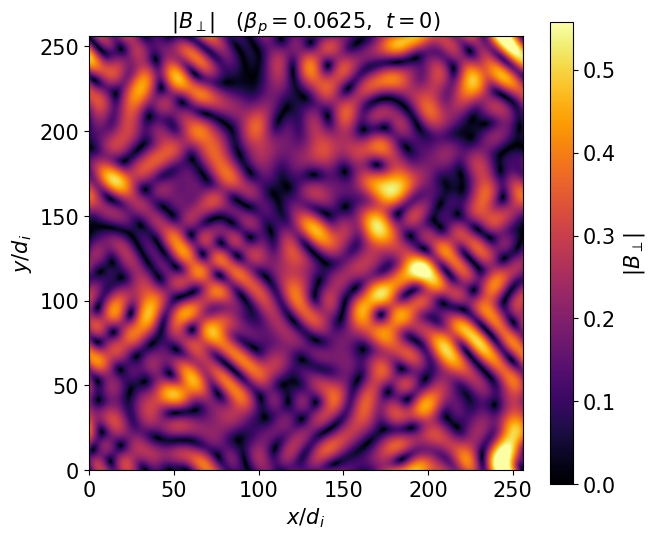

In [2]:
# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir
RESULTS = results_dir("paper1_methods")
# ================================================================
#  Simple animation of |B_perp| = sqrt(Bx^2 + By^2) over time
#  (B_perp is the in-plane field, perpendicular to the z guide field)
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta      = 0.0625                                  # which run
times     = range(0, 11)                      # snapshots to animate (reduce if low on memory)
# base_path = f"/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_{beta}/beta_e_1/"
base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
dx        = 0.0625                             # grid spacing (only used for axis labels in d_i)
out_file  = str(RESULTS / "Bperp_animation.mp4")
fps       = 1


# ---------- load one field from its HDF5 file ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


# ---------- build every frame: |B_perp| = sqrt(Bx^2 + By^2) ----------
frames = []
frame_times = []
for t in times:
    try:
        Bx = load("Bx", t)
        By = load("By", t)
    except FileNotFoundError:
        continue                               # skip a missing snapshot
    frames.append(np.sqrt(Bx**2 + By**2))
    frame_times.append(t)
    print(f"loaded t={t}", flush=True)

# ---------- one fixed colour scale for the whole movie (so it doesn't flicker) ----------
vmax   = max(np.percentile(f, 99.5) for f in frames)
Nx, Ny = frames[0].shape
extent = [0, Nx * dx, 0, Ny * dx]              # axes in d_i

# ---------- draw the first frame ----------
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(frames[0].T, origin="lower", extent=extent,
               cmap="inferno", vmin=0, vmax=vmax)
fig.colorbar(im, label=r"$|B_\perp|$")
ax.set_xlabel(r"$x / d_i$")
ax.set_ylabel(r"$y / d_i$")


# ---------- update function: swap in the next frame ----------
def update(i):
    im.set_data(frames[i].T)
    ax.set_title(rf"$|B_\perp|$   ($\beta_p={beta}$,  $t={frame_times[i]}$)")
    return [im]


# ---------- make and save the animation ----------
anim = FuncAnimation(fig, update, frames=len(frames), interval=3000 / fps)
anim.save(out_file, writer="ffmpeg", fps=fps)
print(f"saved {out_file}")

In [6]:
# ================================================================
#  Simple animation of |B_perp| = sqrt(Bx^2 + By^2) over time
#  (B_perp is the in-plane field, perpendicular to the z guide field)
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta      = 0.0625                                  # which run
times     = range(0, 56)                      # snapshots to animate (reduce if low on memory)
# base_path = f"/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_{beta}/beta_e_1/"
base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
dx        = 0.0625                             # grid spacing (only used for axis labels in d_i)
out_file  = str(RESULTS / "Bperp_animation.mp4")
fps       = 1


# ---------- load one field from its HDF5 file ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


Bx = load("Bx", t)
By = load("By", t)

Bperp = np.sqrt(Bx**2 + By**2)
plt.figure(figsize=(10, 8))

img = plt.imshow(
    Bperp,
    cmap='inferno',
    vmin=0,
    vmax=0.5
)

plt.colorbar(img)

plt.title(r'$|B^2|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig(RESULTS / 'Bperp.png', dpi=300)
plt.show()

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_0.0625/beta_e_0.0625/Bx_ApJ_t56.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
#Lets Plot J_Parallel

File_Bx = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bx_ApJ_t200.h5'
File_By = f'{DATA_ROOT}/beta_p_1/beta_e_1/By_ApJ_t200.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

data_Bx = iterative_filtering1D(data_Bx, 2)
data_By = iterative_filtering1D(data_By, 2)

#Compute J_parallel using Fourier Transform
J_par_FT = partial_x_fft(data_By,dx)-partial_y_fft(data_Bx,dy)
J_par_mod = np.abs(J_par_FT)

Nx, Ny = J_par_mod.shape

Lx = Nx * dx
Ly = Ny * dy

dx = dy = 0.0625

Nx, Ny = J_par_mod.shape

extent = [0, Nx*dx, 0, Ny*dy]

plt.figure(figsize=(10, 8))

img = plt.imshow(
    J_par_mod,
    cmap='inferno',
    vmin=0,
    vmax=0.5,
    extent=extent
)

plt.colorbar(img)

plt.title(r'$|J_\parallel|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig(RESULTS / 'Jpar200.png', dpi=300)
plt.show()

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta = 0.0625
times = range(0, 56)

base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
out_dir = str(RESULTS / "Bperp_frames")

os.makedirs(out_dir, exist_ok=True)


# ---------- load one field ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


# ---------- loop over times ----------
for t in times:

    Bx = load("Bx", t)
    By = load("By", t)

    Bperp = np.sqrt(Bx**2 + By**2)

    fig, ax = plt.subplots(figsize=(10, 8))

    img = ax.imshow(
        Bperp,
        cmap="inferno",
        vmin=0,
        vmax=0.5,
        origin="lower"
    )

    fig.colorbar(img, ax=ax, label=r"$|B_\perp|$")

    ax.set_title(f"$|B_\\perp|$, t = {t}", fontsize=25)
    ax.set_xlabel(r"$x/d_p$", fontsize=20)
    ax.set_ylabel(r"$y/d_p$", fontsize=20)

    plt.tight_layout()

    fig.savefig(
        f"{out_dir}/Bperp_t{t:03d}.png",
        dpi=300
    )

    plt.close(fig)

print(f"Saved {len(times)} frames to {out_dir}/")

Saved 56 frames to Bperp_frames/


In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta = 0.0625
times = range(0, 56)

base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
out_dir = str(RESULTS / "Bz_frames")

os.makedirs(out_dir, exist_ok=True)


# ---------- load one field ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


# ---------- loop over times ----------
for t in times:

    Bz = load("Bz", t)

    fig, ax = plt.subplots(figsize=(10, 8))

    img = ax.imshow(
        Bz,
        cmap="inferno",
        vmin=0,
        vmax=0.5,
        origin="lower"
    )

    fig.colorbar(img, ax=ax, label=r"$|B_\perp|$")

    ax.set_title(f"$|B_\\perp|$, t = {t}", fontsize=25)
    ax.set_xlabel(r"$x/d_p$", fontsize=20)
    ax.set_ylabel(r"$y/d_p$", fontsize=20)

    plt.tight_layout()

    fig.savefig(
        f"{out_dir}/Bz_t{t:03d}.png",
        dpi=300
    )

    plt.close(fig)

print(f"Saved {len(times)} frames to {out_dir}/")

Saved 56 frames to Bz_frames/


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta = 0.0625
times = range(0, 56)

base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
out_dir = str(RESULTS / "Dn1_frames")

os.makedirs(out_dir, exist_ok=True)


# ---------- load one field ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


# ---------- loop over times ----------
for t in times:

    Dn1 = load("Dn1", t)

    fig, ax = plt.subplots(figsize=(10, 8))

    img = ax.imshow(
        Dn1,
        cmap="inferno",
        origin="lower"
    )

    fig.colorbar(img, ax=ax, label=r"$|B_\perp|$")

    ax.set_title(f"$|Dn1$, t = {t}", fontsize=25)
    ax.set_xlabel(r"$x/d_p$", fontsize=20)
    ax.set_ylabel(r"$y/d_p$", fontsize=20)

    plt.tight_layout()

    fig.savefig(
        f"{out_dir}/Dn1_t{t:03d}.png",
        dpi=300
    )

    plt.close(fig)

print(f"Saved {len(times)} frames to {out_dir}/")

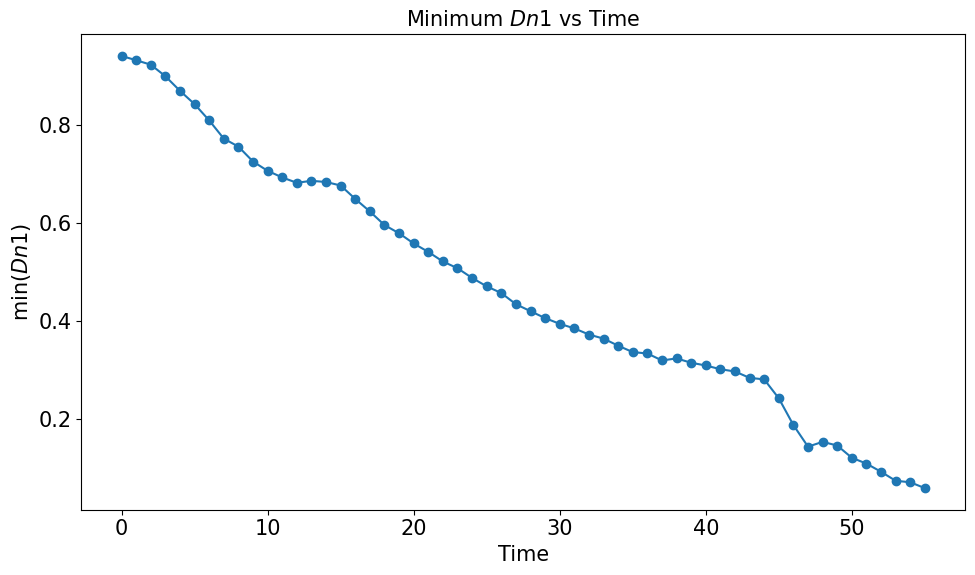

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
times = range(0, 56)

base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"

min_Dn1 = []

def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


for t in times:

    Dn1 = load("Dn1", t)

    min_Dn1.append(np.min(Dn1))


# Convert to numpy array
min_Dn1 = np.array(min_Dn1)

# Plot time series
plt.figure(figsize=(10, 6))

plt.plot(times, min_Dn1, marker='o')

plt.xlabel("Time")
plt.ylabel(r"$\min(Dn1)$")
plt.title(r"Minimum $Dn1$ vs Time")

plt.tight_layout()
plt.savefig(RESULTS / "min_Dn1_timeseries.png", dpi=300)
plt.show()

In [3]:
np.min(min_Dn1)

np.float32(0.058285814)

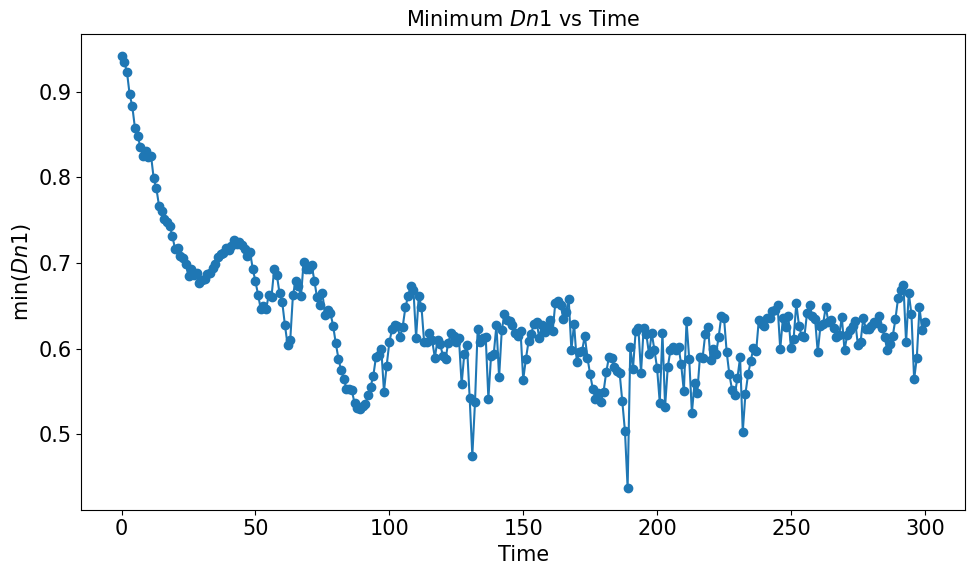

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
times = range(0, 301)

base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1/"

min_Dn1 = []

for t in times:

    Dn1 = load("Dn1", t)

    min_Dn1.append(np.min(Dn1))


# Convert to numpy array
min_Dn1 = np.array(min_Dn1)

# Plot time series
plt.figure(figsize=(10, 6))

plt.plot(times, min_Dn1, marker='o')

plt.xlabel("Time")
plt.ylabel(r"$\min(Dn1)$")
plt.title(r"Minimum $Dn1$ vs Time")

plt.tight_layout()
plt.savefig(RESULTS / "min_Dn1_timeseries.png", dpi=300)
plt.show()

In [10]:
np.min(min_Dn1)

np.float32(0.43695012)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta = 0.0625
times = range(0, 56)

base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
out_dir = str(RESULTS / "ETotal_frames")

os.makedirs(out_dir, exist_ok=True)


# ---------- load one field ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


# ---------- loop over times ----------
for t in times:

    Ex = load("Ex", t)
    Ey = load("Ey", t)
    Ez = load("Ez", t)

    Etotal = np.sqrt(Ex**2 + Ey**2 + Ez**2)

    fig, ax = plt.subplots(figsize=(10, 8))

    img = ax.imshow(
        Etotal,
        cmap="inferno",
        origin="lower"
    )

    fig.colorbar(img, ax=ax, label=r"$|Etotal|$")

    ax.set_title(f"$|Etotal|$, t = {t}", fontsize=25)
    ax.set_xlabel(r"$x/d_p$", fontsize=20)
    ax.set_ylabel(r"$y/d_p$", fontsize=20)

    plt.tight_layout()

    fig.savefig(
        f"{out_dir}/Etotal{t:03d}.png",
        dpi=300
    )

    plt.close(fig)

print(f"Saved {len(times)} frames to {out_dir}/")

Saved 56 frames to ETotal_frames/


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# ---------- settings ----------
beta = 0.0625
times = range(55, 56)

base_path = f"{DATA_ROOT}/beta_p_0.0625/beta_e_0.0625/"
out_dir = str(RESULTS / "ETotal_frames")

os.makedirs(out_dir, exist_ok=True)


# ---------- load one field ----------
def load(tag, t):
    with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
        return f["DS1"][:].T


# ---------- loop over times ----------
for t in times:

    Ex = load("Ex", t)
    Ey = load("Ey", t)
    Ez = load("Ez", t)

    Etotal = np.sqrt(Ex**2 + Ey**2 + Ez**2)

    fig, ax = plt.subplots(figsize=(10, 8))

    img = ax.imshow(
        Etotal,
        cmap="inferno",
        origin="lower"
    )

    fig.colorbar(img, ax=ax, label=r"$|Etotal|$")

    ax.set_title(f"$|Etotal|$, t = {t}", fontsize=25)
    ax.set_xlabel(r"$x/d_p$", fontsize=20)
    ax.set_ylabel(r"$y/d_p$", fontsize=20)

    plt.tight_layout()

    fig.savefig(
        f"{out_dir}/Etotal{t:03d}.png",
        dpi=300
    )

    plt.close(fig)

print(f"Saved {len(times)} frames to {out_dir}/")